# 03c · Random Forest — Bike Sharing Demand

**Responsable:** José · **Plan:** `project_plan_crisp_dm.md` §6.2 · `plan_sprints.md` §5 (Sprint 2)

**Pregunta:** ¿cuánto mejora un modelo de bagging (Random Forest) al baseline de calendario (0.5585) y cómo queda frente a Ridge (0.4885) y LightGBM (0.4549)? ¿Ayudan los lags?

**Protocolo (igual que los notebooks 03 y 03b):** solo **train** (2011-01-01 a 2012-06-30), `get_cv()` (5 folds, ventana expansiva) y `validar_temporal`. Target `log1p(cnt)`, métrica de decisión **RMSLE**. El test no se usa. Todo ajuste ocurre dentro del pipeline con el train de cada fold.

**Regla de adopción** (`CONFIG["regla_adopcion"]`): mejora media ≥ 0.002 **y** peor en ≤ 1 de 5 folds.

## 1) Preparación del entorno

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, agregar_lags
from src.evaluate import get_cv, validar_temporal

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "jose" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = CONFIG["dir_reports"] / "jose"

# Referencias medidas por Joan y Pardo (docs/sprints/resumen_sprint_2_joan.md y resumen_sprint_2_pardo.md)
REF = {"Baseline calendario": 0.5585, "Ridge final": 0.4885, "LightGBM + tuning": 0.4549, "LightGBM + lags (gap=24)": 0.3905}

### ✅ Punto de control 1

In [2]:
assert RANDOM_STATE == 42 and CONFIG["cv"]["n_splits"] == 5
print("✅ Configuración lista.")

✅ Configuración lista.


## 2) Datos de train

`X_tr`, `y_tr` salen del contrato de Joan. Los NaN de las 125 horas ausentes ya fueron retirados por `separar_xy`.

In [3]:
df = load_data()
X_tr, y_tr = separar_xy(temporal_split(df)[0])
assert X_tr.index.max() == pd.Timestamp(CONFIG["ultima_hora_train"]) and X_tr.index.is_monotonic_increasing
cv = get_cv()
print(X_tr.shape, X_tr.index.min(), "→", X_tr.index.max())
for k, (a, b) in enumerate(cv.split(X_tr), 1):
    print(f"fold {k}: train hasta {X_tr.index[a[-1]]:%Y-%m-%d} | valida {X_tr.index[b[0]]:%Y-%m-%d} → {X_tr.index[b[-1]]:%Y-%m-%d}")

(13003, 13) 2011-01-01 00:00:00 → 2012-06-30 23:00:00
fold 1: train hasta 2011-08-31 | valida 2011-08-31 → 2011-10-31
fold 2: train hasta 2011-10-31 | valida 2011-10-31 → 2011-12-31
fold 3: train hasta 2011-12-31 | valida 2011-12-31 → 2012-03-01
fold 4: train hasta 2012-03-01 | valida 2012-03-01 → 2012-05-01
fold 5: train hasta 2012-05-01 | valida 2012-05-01 → 2012-06-30


### ✅ Punto de control 2
Cada fold valida **después** de su train (la función `validar_temporal` además lo verifica con un `assert`). Los árboles no necesitan escalado: `build_preprocessor(escalar=False)`, `hora='entero'`, `tendencia='yr'` (valores de `CONFIG["features"]`, confirmados con LightGBM; para RF siguen siendo provisionales).

## 3) Random Forest base

Configuración por defecto de scikit-learn salvo `n_estimators=300`. Se mide con `validar_temporal` (el preprocesador se re-ajusta con el train de cada fold).

In [4]:
def rf_pipe(n_estimators=300, **params):
    return Pipeline([("prep", build_preprocessor()),
                     ("modelo", RandomForestRegressor(n_estimators=n_estimators, n_jobs=-1,
                                                      random_state=RANDOM_STATE, **params))])

RESULTADOS = {}   # nombre -> (por_fold, resumen)
def medir(nombre, pipe, X=X_tr, y=y_tr, cv=None):
    t0 = time.perf_counter()
    pf, res = validar_temporal(pipe, X, y, nombre, cv=cv)
    res["t_total_s"] = time.perf_counter() - t0
    RESULTADOS[nombre] = (pf, res)
    print(f"{nombre}: RMSLE {res['rmsle_media']:.4f} ± {res['rmsle_std']:.4f} | RMSE {res['rmse_media']:.1f} | "
          f"MAE {res['mae_media']:.1f} | R² {res['r2_media']:.3f} | {res['t_total_s']:.0f}s")
    print("   por fold:", " ".join(f"{v:.4f}" for v in pf["rmsle"]))
    return pf, res

pf_base, res_base = medir("RF base (sin lags)", rf_pipe())

RF base (sin lags): RMSLE 0.4887 ± 0.1703 | RMSE 77.7 | MAE 52.5 | R² 0.718 | 13s
   por fold: 0.3946 0.4878 0.7650 0.4825 0.3133


### ✅ Punto de control 3
El RMSLE por fold se puede comparar fold a fold con Joan (LightGBM) y Pardo (Ridge): mismos folds, misma métrica.

In [5]:
assert len(pf_base) == 5 and res_base["rmsle_media"] < REF["Baseline calendario"], "RF base debería superar al baseline"
print("✅ RF base supera al baseline de calendario:", f"{res_base['rmsle_media']:.4f} < {REF['Baseline calendario']}")

✅ RF base supera al baseline de calendario: 0.4887 < 0.5585


## 4) Tuning básico (`max_features`, `min_samples_leaf`, `max_depth`)

Búsqueda aleatoria de **10 candidatos** con `n_estimators=150` (más rápido), evaluados con **los mismos 5 folds temporales** (`validar_temporal`; no hay K-Fold aleatorio). El mejor se vuelve a medir con 300 árboles. Semilla fija.

⚠️ Igual que en el tuning de Joan, los hiperparámetros se eligen con los mismos folds en los que se reporta el puntaje, así que **la cifra es algo optimista** (se anota en la limitación).

In [6]:
ESPACIO = {"max_features": [0.3, 0.5, 0.7, 1.0],
           "min_samples_leaf": [1, 2, 5, 10, 20],
           "max_depth": [None, 15, 25]}
N_ITER = 10
candidatos = list(ParameterSampler(ESPACIO, n_iter=N_ITER, random_state=RANDOM_STATE))
filas = []
for i, p in enumerate(candidatos, 1):
    pf, res = validar_temporal(rf_pipe(n_estimators=150, **p), X_tr, y_tr, f"cand{i}")
    filas.append({**p, "rmsle_media": res["rmsle_media"], "rmsle_std": res["rmsle_std"],
                  **{f"f{k}": v for k, v in enumerate(pf["rmsle"], 1)}})
    print(i, p, f"→ {res['rmsle_media']:.4f}")
busqueda = pd.DataFrame(filas).sort_values("rmsle_media").reset_index(drop=True)
busqueda.round(4)

1 {'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None} → 0.4890


2 {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None} → 0.4834


3 {'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 15} → 0.4899


4 {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 25} → 0.4830


5 {'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': None} → 0.5008


...

7 {'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 15} → 0.5038


8 {'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 25} → 0.5023


9 {'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': None} → 0.4883


10 {'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 25} → 0.4953


,min_samples_leaf,max_features,max_depth,rmsle_media,rmsle_std,f1,f2,f3,f4,f5
0,1,0.5,25.0,0.4830,0.1737,0.3804,0.4544,0.7612,0.5124,0.3067
1,1,0.5,NaN,0.4834,0.1736,0.3826,0.4564,0.7631,0.5075,0.3075
2,5,0.7,NaN,0.4883,0.1680,0.3998,0.4694,0.7602,0.4991,0.3130
3,1,0.3,NaN,0.4890,0.1716,0.3871,0.4563,0.7625,0.5242,0.3148
4,2,1.0,15.0,0.4899,0.1715,0.3950,0.4957,0.7647,0.4863,0.3079
5,5,1.0,25.0,0.4953,0.1667,0.4079,0.5062,0.7607,0.4877,0.3140
6,10,0.7,NaN,0.5008,0.1636,0.4116,0.4895,0.7626,0.5134,0.3268
7,10,0.5,25.0,0.5023,0.1650,0.4075,0.4820,0.7662,0.5248,0.3309
8,10,0.7,15.0,0.5038,0.1652,0.4147,0.4907,0.7689,0.5161,0.3287
9,20,0.7,25.0,0.5147,0.1527,0.4320,0.4969,0.7589,0.5328,0.3529


In [7]:
MEJOR = {k: (None if pd.isna(v) else v) for k, v in busqueda.loc[0, list(ESPACIO)].items()}
MEJOR = {"max_features": float(MEJOR["max_features"]), "min_samples_leaf": int(MEJOR["min_samples_leaf"]),
         "max_depth": None if MEJOR["max_depth"] is None else int(MEJOR["max_depth"])}
print("Mejor configuración:", MEJOR)
pf_tun, res_tun = medir("RF + tuning (sin lags)", rf_pipe(**MEJOR))

Mejor configuración: {'max_features': 0.5, 'min_samples_leaf': 1, 'max_depth': 25}


RF + tuning (sin lags): RMSLE 0.4827 ± 0.1748 | RMSE 79.1 | MAE 53.9 | R² 0.706 | 7s
   por fold: 0.3780 0.4544 0.7630 0.5114 0.3063


### ✅ Punto de control 4
Se aplica la regla de adopción del grupo (mejora ≥ 0.002 y peor en ≤ 1 fold) al tuning frente al RF base.

In [8]:
def regla(ref_pf, var_pf, nombre):
    d = ref_pf["rmsle"].to_numpy() - var_pf["rmsle"].to_numpy()      # >0 = la variante mejora
    mejora = d.mean()
    peor = int((d < 0).sum())
    ok = mejora >= CONFIG["regla_adopcion"]["min_mejora_rmsle"] and peor <= CONFIG["regla_adopcion"]["max_folds_peor"]
    print(f"{nombre}: mejora media {mejora:+.4f} | mejor en {int((d>0).sum())}/5, peor en {peor}/5 → {'ADOPTAR' if ok else 'DESCARTAR'}")
    return ok, mejora, peor

ok_tuning, _, _ = regla(pf_base, pf_tun, "Tuning vs RF base")

Tuning vs RF base: mejora media +0.0060 | mejor en 4/5, peor en 1/5 → ADOPTAR


## 5) Lags (`lag_24`, `lag_168`) — solo con horizonte «día siguiente»

Para que la tabla sea justa se reporta **con y sin lags** bajo la misma validación (`get_cv(gap=24)`). Los lags valen solo si el día anterior está completo; los árboles de scikit-learn aceptan los NaN de los lags (132 y 265 filas en train).

In [9]:
X_l, y_l = separar_xy(temporal_split(agregar_lags(df))[0])
cv24 = get_cv(gap=CONFIG["lgbm"]["gap_con_lags"])
LAGS = CONFIG["lgbm"]["lags"]

def rf_lags_pipe(**params):
    return Pipeline([("prep", build_preprocessor(lags=LAGS)),
                     ("modelo", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **params))])

pf_ref24, _ = medir("RF tuneado, gap=24 (sin lags)", rf_pipe(**MEJOR), X=X_tr, y=y_tr, cv=cv24)
pf_lag, res_lag = medir("RF tuneado + lag_24 + lag_168, gap=24", rf_lags_pipe(**MEJOR), X=X_l, y=y_l, cv=cv24)
ok_lags, _, _ = regla(pf_ref24, pf_lag, "Lags vs sin lags (gap=24)")

RF tuneado, gap=24 (sin lags): RMSLE 0.4828 ± 0.1748 | RMSE 79.2 | MAE 53.9 | R² 0.705 | 7s
   por fold: 0.3800 0.4571 0.7638 0.5075 0.3055


RF tuneado + lag_24 + lag_168, gap=24: RMSLE 0.4124 ± 0.0599 | RMSE 70.9 | MAE 43.8 | R² 0.795 | 10s
   por fold: 0.4176 0.4690 0.4595 0.3964 0.3195
Lags vs sin lags (gap=24): mejora media +0.0704 | mejor en 2/5, peor en 3/5 → DESCARTAR


## 6) Tabla de resultados y figura

In [10]:
filas = [{"Modelo": "Baseline calendario (Joan)", "RMSLE": REF["Baseline calendario"], "std": 0.0601},
         {"Modelo": "Ridge final (Pardo)", "RMSLE": REF["Ridge final"], "std": 0.1583},
         {"Modelo": "LightGBM + tuning (Joan)", "RMSLE": REF["LightGBM + tuning"], "std": 0.1918}]
for nombre, (pf, res) in RESULTADOS.items():
    filas.append({"Modelo": nombre, "RMSLE": res["rmsle_media"], "std": res["rmsle_std"],
                  "RMSE": res["rmse_media"], "MAE": res["mae_media"], "R2": res["r2_media"],
                  **{f"f{k}": v for k, v in enumerate(pf["rmsle"], 1)}})
tabla = pd.DataFrame(filas)
tabla.round(4).to_csv(REP_DIR / "rf_resultados.csv", index=False)
tabla.round(4)

,Modelo,RMSLE,std,RMSE,MAE,R2,f1,f2,f3,f4,f5
0,Baseline calendario (Joan),0.5585,0.0601,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ridge final (Pardo),0.4885,0.1583,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LightGBM + tuning (Joan),0.4549,0.1918,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RF base (sin lags),0.4887,0.1703,77.6735,52.5244,0.7176,0.3946,0.4878,0.7650,0.4825,0.3133
4,RF + tuning (sin lags),0.4827,0.1748,79.0694,53.8623,0.7062,0.3780,0.4544,0.7630,0.5114,0.3063
5,"RF tuneado, gap=24 (sin lags)",0.4828,0.1748,79.2335,53.8602,0.7053,0.3800,0.4571,0.7638,0.5075,0.3055
6,"RF tuneado + lag_24 + lag_168, gap=24",0.4124,0.0599,70.9062,43.8171,0.7953,0.4176,0.4690,0.4595,0.3964,0.3195


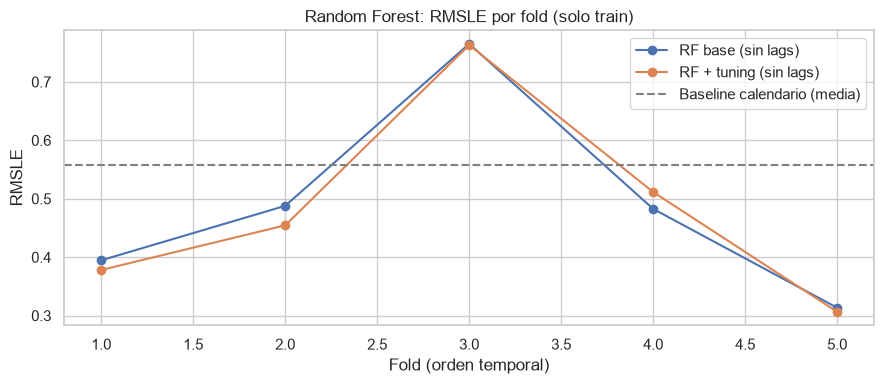

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for nombre in ["RF base (sin lags)", "RF + tuning (sin lags)"]:
    pf = RESULTADOS[nombre][0]
    ax.plot(pf["fold"], pf["rmsle"], marker="o", label=nombre)
ax.axhline(REF["Baseline calendario"], color="gray", ls="--", label="Baseline calendario (media)")
ax.set(xlabel="Fold (orden temporal)", ylabel="RMSLE", title="Random Forest: RMSLE por fold (solo train)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / "01_rf_rmsle_por_fold.png", dpi=130); plt.show()

## 7) Importancia de variables (informativa)

Importancia por **permutación** sobre el último fold (ajustado con el train de ese fold), en RMSLE. Es una vista rápida; la interpretabilidad del modelo final es del Sprint 3.

hr            1.5882
workingday    0.3368
weathersit    0.0591
weekday       0.0392
hum           0.0273
temp          0.0175
atemp         0.0059
windspeed     0.0044
season        0.0026
mnth          0.0003
dtype: float64


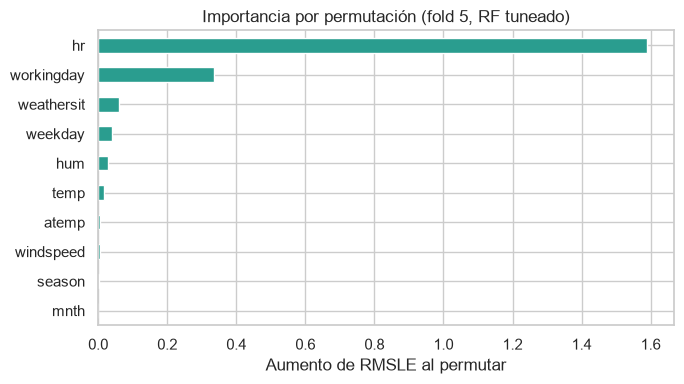

In [12]:
from sklearn.inspection import permutation_importance
i_tr, i_va = list(cv.split(X_tr))[-1]
m = clone(rf_pipe(**MEJOR)).fit(X_tr.iloc[i_tr], np.log1p(np.asarray(y_tr, dtype=float)[i_tr]))
Xv = X_tr.iloc[i_va]; yv = np.log1p(np.asarray(y_tr, dtype=float)[i_va])
pi = permutation_importance(m, Xv, yv, scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=Xv.columns).sort_values(ascending=False)
print(imp.round(4).head(10))
fig, ax = plt.subplots(figsize=(7, 4))
imp.head(10)[::-1].plot.barh(ax=ax, color="#2a9d8f"); ax.set(xlabel="Aumento de RMSLE al permutar", title="Importancia por permutación (fold 5, RF tuneado)")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_rf_importancia.png", dpi=130); plt.show()

## 8) Guardar modelo (para el Sprint 3)

Se ajusta con **todo train** (sin test) y se guarda en `models/` (carpeta ignorada por git; se regenera con este notebook).

In [13]:
X_fin, y_fin = (X_l, y_l) if ok_lags else (X_tr, y_tr)
pipe_final = rf_lags_pipe(**MEJOR) if ok_lags else rf_pipe(**MEJOR)
pipe_final.fit(X_fin, np.log1p(np.asarray(y_fin, dtype=float)))
CONFIG["dir_models"].mkdir(exist_ok=True)
joblib.dump({"pipeline": pipe_final, "log_target": True, "params": MEJOR, "con_lags": bool(ok_lags)}, CONFIG["dir_models"] / "rf_jose.joblib")
print("Modelo guardado. con_lags =", ok_lags)

Modelo guardado. con_lags = False


## 9) Conclusiones del Random Forest (se completan con los números de arriba)

Ver `docs/sprints/resumen_sprint_2_jose.md` y la ficha en `reports/decisiones.md`.